## DimeNet++: fixed edge-noise pilot

Ethanol CCSD(T), Gold only. Two matched 20-epoch fine-tuning arms from the same 200-epoch checkpoint. This is an independent DimeNet++ experiment, not the team-wide three-phase MPNN benchmark or a BLIP implementation. These cells read saved results and generate analysis; they do not claim to rerun training.

In [1]:
from pathlib import Path
import json
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Image
def display_png(path):
    display(Image(filename=str(path)))
root = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p/'ml/models/dimenet.py').exists()), None)
if root is None:
    raise RuntimeError('Open this notebook inside the project repository')
import sys
if str(root) not in sys.path:
    sys.path.insert(0, str(root))
out = root/'notebooks/dongxiao_dimenet/edge_noise'
run = root/'experiments/results/dongxiao_edge_noise_20'
r = json.loads((out/'metrics.json').read_text())
print('Status:', r['status'], '| Test evaluated:', r['test_evaluated'])
print('Saved Gold train / validation:', len(r['selected_gold_indices']['train']), '/', len(r['selected_gold_indices']['val']))
print('Gold SHA256:', r['gold_sha256'])
print('Initial checkpoint SHA256:', r['initial_checkpoint_sha256'])


Status: completed | Test evaluated: False
Saved Gold train / validation: 889 / 111
Gold SHA256: 8e6571e1c0f0ac5a4fbab8a3236c26abff0095f54772866ad6ffa7f525deb441
Initial checkpoint SHA256: 861ce3d11d8cf24fe79feb2e393c3738a37f9bff5bb206c5180674f72c221ba0


## 1. Controlled protocol

Both arms use all 889 saved training structures and all 111 validation structures, seed 42, fresh Adam optimizers, identical batch order, learning rate 0.0001 and energy MSE + 100 × force-component MSE. Each arm receives exactly 20 additional epochs. Initial centering uses training energies only. No additive energy correction is applied here. Noise standard deviation 0.05 was fixed before this run; it was not tuned. Checkpoint selection considers epochs 1–20 using validation MC-mean joint MSE (8 draws for noise; 1 for control). Final validation uses a separate random stream with 32 draws. Validation still informed selection, so these are exploratory results.

In [2]:
print(json.dumps(r['config'], indent=2))


{
  "name": "dongxiao_edge_noise_20",
  "initial_checkpoint": "experiments/results/dongxiao_dimenet_ethanol_lr1e4_200/best.pt",
  "data": {
    "dataset": "md17",
    "molecule": "ethanol",
    "theory": "ccsd_t",
    "gold_path": "data/gold/md17/ethanol_ccsd_t.npz",
    "cutoff_radius": 5.0,
    "seed": 42,
    "max_train_samples": 889,
    "max_val_samples": 111
  },
  "model": {
    "name": "dimenetplusplus",
    "hidden_channels": 16,
    "out_channels": 1,
    "num_blocks": 1,
    "int_emb_size": 8,
    "basis_emb_size": 4,
    "out_emb_channels": 16,
    "num_spherical": 3,
    "num_radial": 3
  },
  "arms": [
    {
      "name": "deterministic",
      "noise_std": 0.0
    },
    {
      "name": "edge_gaussian",
      "noise_std": 0.05
    }
  ],
  "train": {
    "epochs": 20,
    "batch_size": 4,
    "lr": 0.0001,
    "energy_loss_weight": 1.0,
    "force_loss_weight": 100.0,
    "device": "cpu",
    "num_threads": 2,
    "output_dir": "experiments/results/dongxiao_edge_noise_20

## 2. Model implementation and physical checks

The initial directed-edge embedding is multiplied by (1 + 0.05 × epsilon), with one independent standard-normal scalar per directed edge shared across channels. The same stochastic forward produces energy and its force gradient. Topology, distances, angles and atomic numbers are preserved. Noise is active during both training and MC evaluation. Geometry tests couple the same edge noise across transformations; permutation tests map noise with edge identity. This fixed-noise regularization baseline is not a learned Bayesian posterior or proof of calibrated uncertainty.

In [3]:
print((root/'ml/models/dongxiao_edge_noise.py').read_text())


"""Independent fixed Gaussian edge-feature baseline; not a BLIP implementation."""
import math
import torch
from ml.models.dimenet import GoldDimeNetPlusPlus


class EdgeNoiseDimeNet(GoldDimeNetPlusPlus):
    """Multiply initial directed-edge embeddings by 1 + sigma * epsilon.

    One scalar N(0,1) per directed edge, shared across feature channels.
    Noise remains active in evaluation for explicit Monte Carlo prediction.
    Pass data.edge_noise to couple samples in geometry/derivative checks.
    Distances, angles, topology and atomic numbers are never perturbed.
    """
    def __init__(self, *args, noise_std=0.05, **kwargs):
        super().__init__(*args, **kwargs)
        if not math.isfinite(noise_std) or noise_std < 0:
            raise ValueError('noise_std must be finite and nonnegative')
        self.noise_std = float(noise_std)
        self._fixed_noise = None
        self.emb.register_forward_hook(self._perturb_edges)

    def _perturb_edges(self, module, inputs, output)

## 3. Matched validation performance

The comparison below uses raw centered energy errors and force-component errors. Do not compare these energy values directly to the previous offset-corrected test results. Lower MAE is better.

deterministic | selected additional epoch: 18 | validation: {
  "energy_mae": 1.128260239969251,
  "force_mae": 1.1309401786987616,
  "energy_mse": 1.5016710007043415,
  "force_mse": 2.400277646450912,
  "uncertainty_available": false
}
edge_gaussian | selected additional epoch: 19 | validation: {
  "energy_mae": 0.4600429968417597,
  "force_mae": 1.2703891897798274,
  "energy_mse": 0.34152845025279216,
  "force_mse": 2.9917182534398243,
  "uncertainty_available": true,
  "energy_spearman": 0.12437697437697436,
  "force_spearman": 0.347016497016497,
  "rejection": [
    {
      "reject_fraction": 0.0,
      "retained_count": 111,
      "force_mae": 1.2703891897798278,
      "random_mean": 1.2703891897798274,
      "random_p05": 1.2703891897798272,
      "random_p95": 1.2703891897798278
    },
    {
      "reject_fraction": 0.1,
      "retained_count": 99,
      "force_mae": 1.2579443841655045,
      "random_mean": 1.2714712033223021,
      "random_p05": 1.2504649124269183,
      "rando

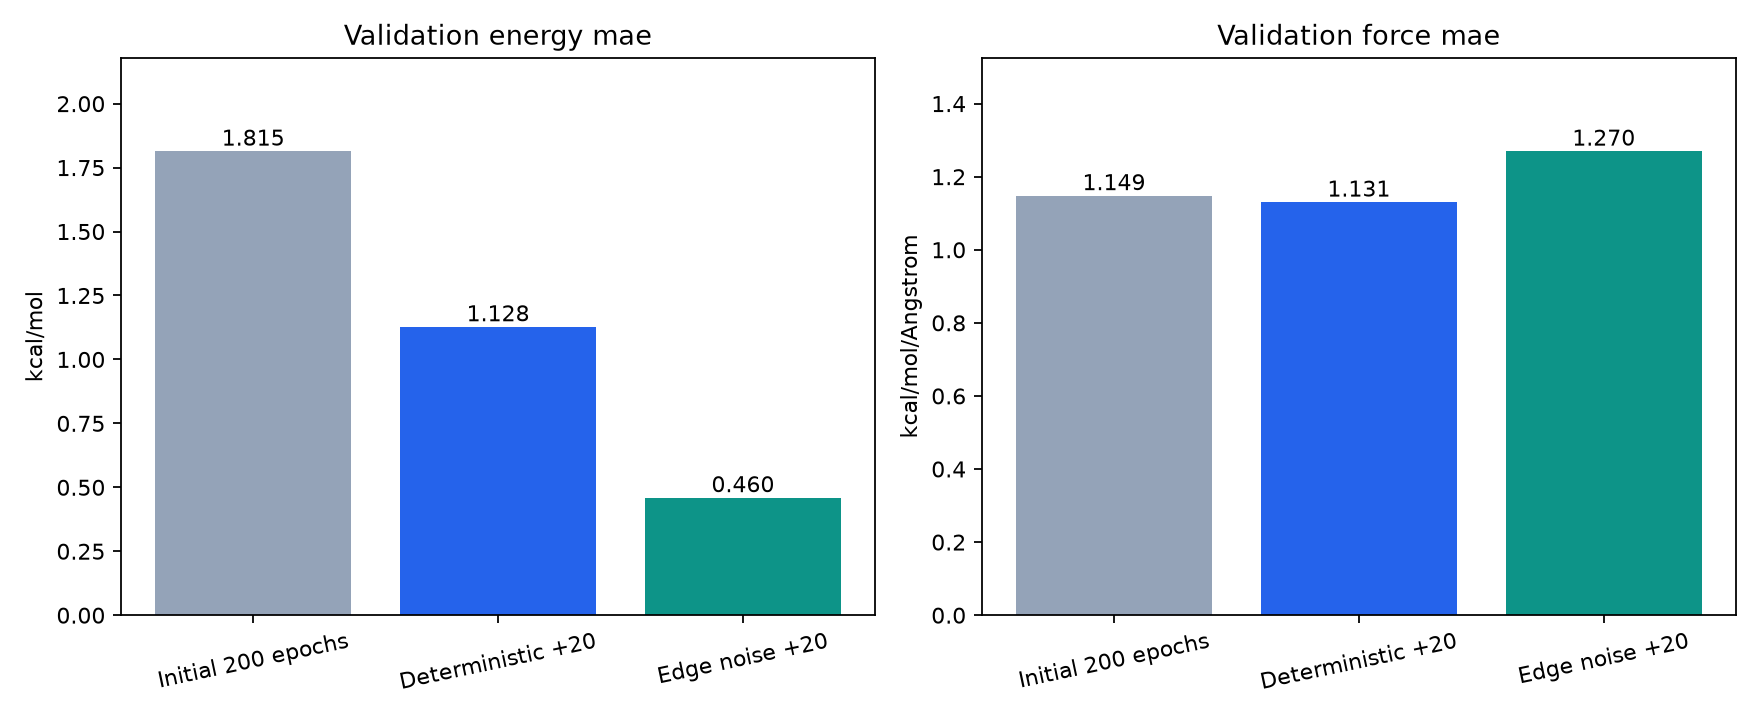

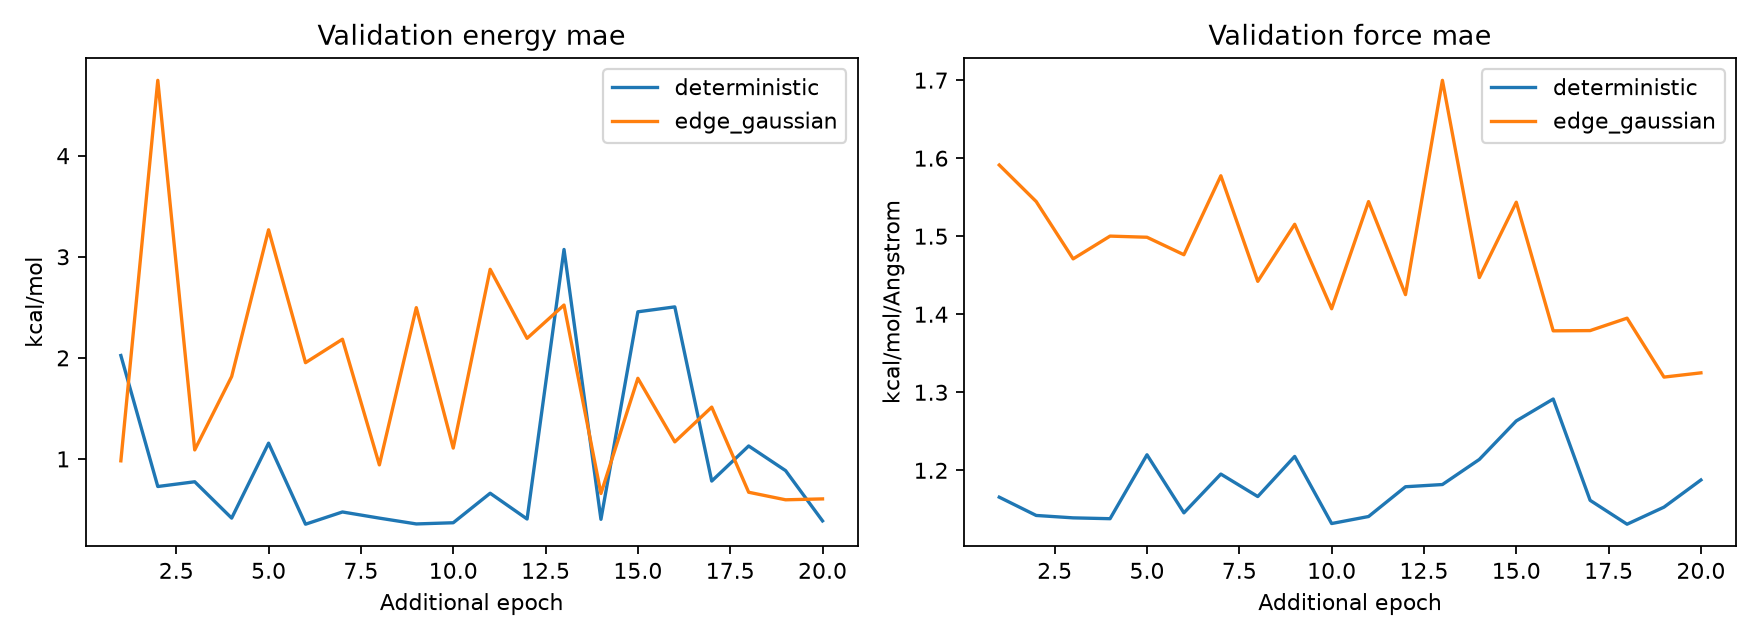

In [4]:
arms = r['arms']
labels = ['Initial 200 epochs', 'Deterministic +20', 'Edge noise +20']
values = [r['initial_validation'], arms['deterministic']['evaluation'], arms['edge_gaussian']['evaluation']]
for name, arm in arms.items():
    print(name, '| selected additional epoch:', arm['best_epoch'], '| validation:', json.dumps(arm['evaluation'], indent=2))
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, metric, unit in zip(axes, ['energy_mae','force_mae'], ['kcal/mol','kcal/mol/Angstrom']):
    bars = ax.bar(labels, [x[metric] for x in values], color=['#94a3b8','#2563eb','#0d9488'])
    ax.bar_label(bars, fmt='%.3f'); ax.set_ylabel(unit); ax.set_title('Validation '+metric.replace('_',' '))
    ax.tick_params(axis='x', labelrotation=12); ax.margins(y=.2)
fig.tight_layout(); fig.savefig(out/'01_matched_validation.png', dpi=160); plt.close(fig)
display_png(out/'01_matched_validation.png')
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for name, arm in arms.items():
    for ax, key in zip(axes, ['energy_mae','force_mae']):
        ax.plot([h['epoch'] for h in arm['history']], [h['validation'][key] for h in arm['history']], label=name)
        ax.set_title('Validation '+key.replace('_',' ')); ax.set_xlabel('Additional epoch'); ax.legend()
axes[0].set_ylabel('kcal/mol'); axes[1].set_ylabel('kcal/mol/Angstrom')
fig.tight_layout(); fig.savefig(out/'02_training_curves.png', dpi=160); plt.close(fig)
display_png(out/'02_training_curves.png')


## 4. Does uncertainty identify larger errors?

Each point is one molecular structure. Energy uncertainty is sample variance across MC energies; energy error is squared MC-mean error. Force uncertainty is the mean component variance over atoms and coordinates; force error is structure-level mean squared error. Spearman correlation measures rank association. It is descriptive on 111 validation structures; no significance or generalization claim is made.

Saved sample metrics independently recomputed and matched.


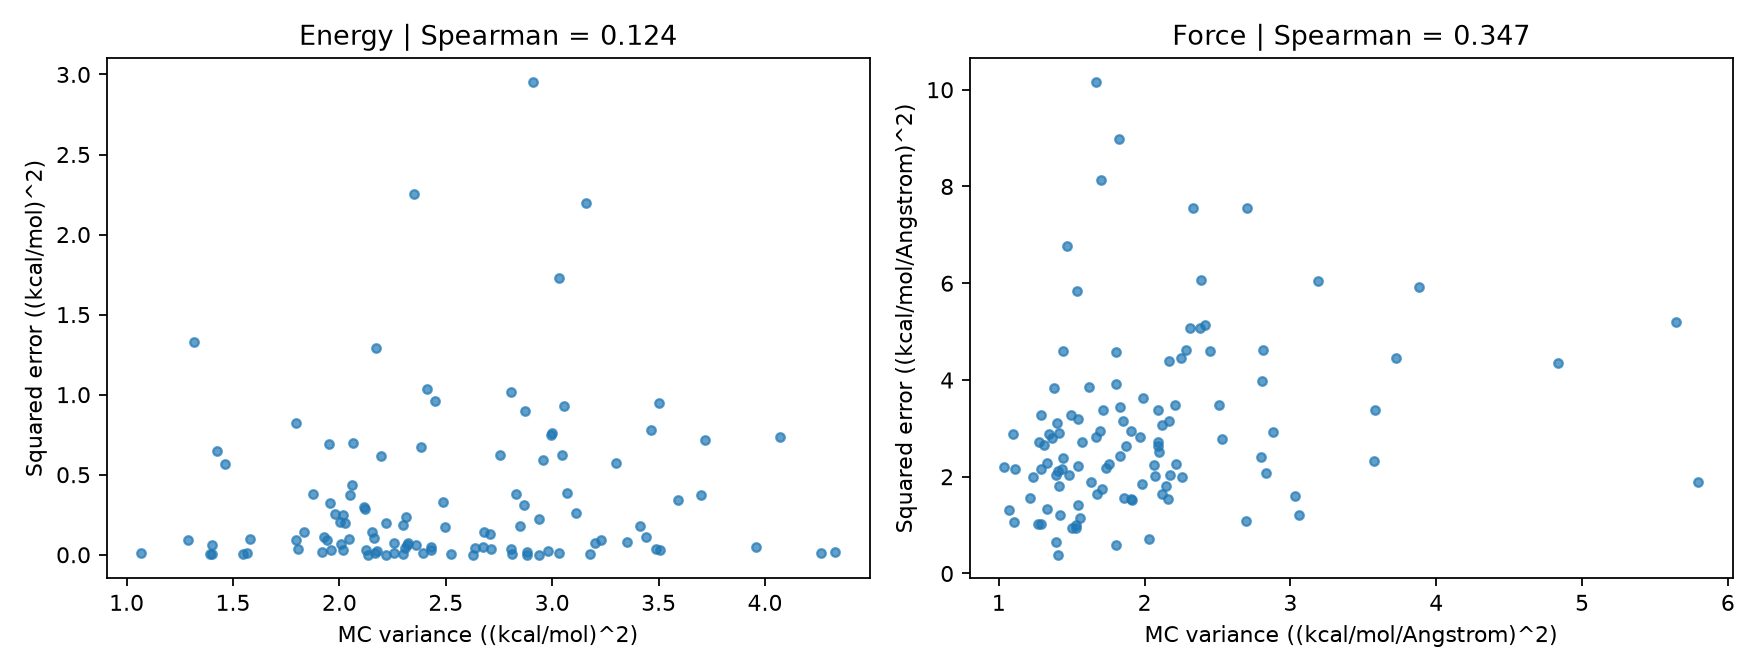

In [5]:
from ml.training.dongxiao_edge_experiment import uq_metrics
with np.load(run/'validation_targets.npz') as z:
    te, tf = z['energy'], z['force']
with np.load(run/'edge_gaussian_validation_samples.npz') as z:
    e, f = z['energy'], z['force']
checked = uq_metrics(e, f, te, tf, r['config']['uncertainty'])
for key in ['energy_mae','force_mae','energy_spearman','force_spearman']:
    assert np.isclose(checked[key], arms['edge_gaussian']['evaluation'][key])
print('Saved sample metrics independently recomputed and matched.')
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
axes[0].scatter(e.var(0,ddof=1), (e.mean(0)-te)**2, s=15, alpha=.7)
axes[1].scatter(f.var(0,ddof=1).mean((1,2)), ((f.mean(0)-tf)**2).mean((1,2)), s=15, alpha=.7)
for ax, kind, unit in zip(axes,['energy','force'], ['(kcal/mol)^2','(kcal/mol/Angstrom)^2']):
    ax.set_xlabel('MC variance ('+unit+')'); ax.set_ylabel('Squared error ('+unit+')')
    ax.set_title(kind.title()+' | Spearman = '+format(checked[kind+'_spearman'], '.3f'))
fig.tight_layout(); fig.savefig(out/'03_uncertainty_error.png', dpi=160); plt.close(fig)
display_png(out/'03_uncertainty_error.png')


## 5. Selective prediction and Monte Carlo cost

Structures with the highest force uncertainty are removed first. The random comparison repeats equally sized random subsets 100 times; its shaded 5th–95th percentile range is a random-selection reference, not a confidence interval on model performance. The 8/16/32-draw comparison uses nested prefixes of one MC stream. Agreement with 32 draws does not establish convergence.

MC 8 | force MAE 1.3221 | force rho 0.3087 | force mean shift vs 32 0.30462 | seconds 0.929
MC 16 | force MAE 1.2876 | force rho 0.3366 | force mean shift vs 32 0.18904 | seconds 1.865
MC 32 | force MAE 1.2704 | force rho 0.347 | force mean shift vs 32 0.0 | seconds 3.747


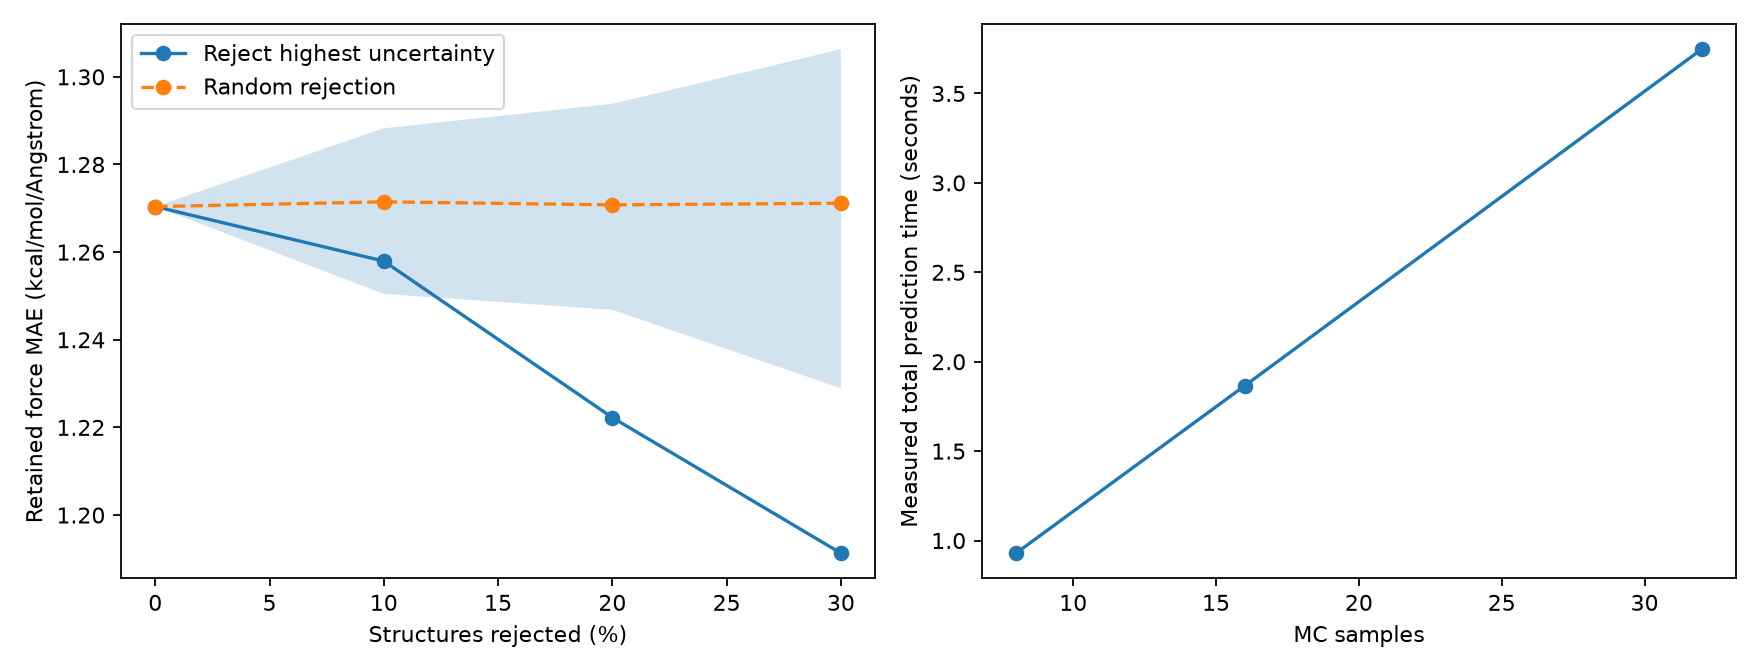

In [6]:
u = arms['edge_gaussian']
rows = u['evaluation']['rejection']; prefixes = u['mc_prefix']
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
x = [100*z['reject_fraction'] for z in rows]
axes[0].plot(x, [z['force_mae'] for z in rows], 'o-', label='Reject highest uncertainty')
axes[0].plot(x, [z['random_mean'] for z in rows], 'o--', label='Random rejection')
axes[0].fill_between(x, [z['random_p05'] for z in rows], [z['random_p95'] for z in rows], alpha=.2)
axes[0].set_xlabel('Structures rejected (%)'); axes[0].set_ylabel('Retained force MAE (kcal/mol/Angstrom)'); axes[0].legend()
axes[1].plot([z['samples'] for z in prefixes], [z['seconds'] for z in prefixes], 'o-')
axes[1].set_xlabel('MC samples'); axes[1].set_ylabel('Measured total prediction time (seconds)')
fig.tight_layout(); fig.savefig(out/'04_rejection_and_cost.png', dpi=160); plt.close(fig)
display_png(out/'04_rejection_and_cost.png')
for z in prefixes:
    print('MC', z['samples'], '| force MAE', round(z['force_mae'],4), '| force rho', round(z['force_spearman'],4),
          '| force mean shift vs 32', round(z['force_mean_shift_to_largest'],5), '| seconds', round(z['seconds'],3))


## 6. Raw energy interval diagnostic

Central empirical quantiles of stochastic energies are compared with reference energies. These are uncalibrated model-sampling intervals, not guaranteed prediction intervals: no observation-noise model or coverage adjustment is fitted. The mean absolute coverage gap across the stated nominal levels is explicitly a regression interval diagnostic, not classification ECE. Only 32 samples are used, making tail quantiles coarse.

Raw interval coverage gap: 0.2426426426426426


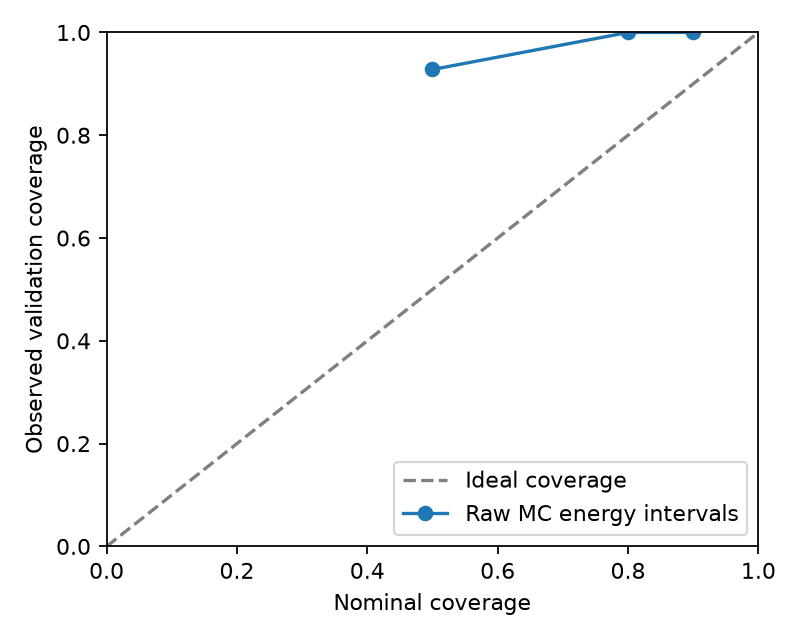

In [7]:
coverage = checked['raw_energy_sample_interval_coverage']
fig, ax = plt.subplots(figsize=(5,4))
ax.plot([0,1],[0,1],'--',color='gray',label='Ideal coverage')
ax.plot([z['nominal'] for z in coverage],[z['observed'] for z in coverage],'o-',label='Raw MC energy intervals')
ax.set(xlabel='Nominal coverage', ylabel='Observed validation coverage', xlim=(0,1), ylim=(0,1))
ax.legend(); fig.tight_layout(); fig.savefig(out/'05_raw_interval_coverage.png',dpi=160); plt.close(fig)
display_png(out/'05_raw_interval_coverage.png')
print('Raw interval coverage gap:', checked['raw_interval_coverage_gap'])


## 7. Findings and limitations

Compared with matched deterministic fine-tuning, edge noise changed raw validation energy MAE from 1.128 to 0.460 kcal/mol and force-component MAE from 1.131 to 1.270 kcal/mol/Angstrom. Force uncertainty/error Spearman was 0.347. Energy MAE improved at the selected checkpoints, while force MAE worsened; the joint objective is dominated by force MSE. This does not demonstrate overall superiority. Removing the nominal highest-uncertainty 30% of structures reduced force MAE within the noisy model to 1.191; this selected subset is not directly comparable to the control on all structures. The nominal 50% raw energy interval covered 92.8% of validation targets, suggesting over-wide intervals in this sample. A completed experiment does not imply an accuracy improvement or calibrated uncertainty. This is one molecule, one training seed and one fixed noise strength, with validation-based selection and no new test evaluation. Previously inspected test results remain historical. Next steps are replication and a team-agreed shared-backbone comparison; do not tune parameters on the historical test set.